# Vehicle Sales Analytics Project 
Objective: Analyze vehicle sales performance and dealer effectiveness using ETL and Exploratory Data Analysis techniques. 


## 1. Import libraries.

In [9]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
sns.set_style("whitegrid")

## 2. Loading and inspecting the dataset.

In [10]:
sales = pd.read_csv("vehicle_sales_raw.csv")
dealers = pd.read_csv("dealers_dim.csv")

In [11]:
sales.head()
sales.info()

dealers.head()
dealers.info()

<class 'pandas.DataFrame'>
RangeIndex: 7110 entries, 0 to 7109
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sale_id            7110 non-null   str    
 1   sale_date          7110 non-null   str    
 2   make               7110 non-null   str    
 3   model              7110 non-null   str    
 4   year               7039 non-null   float64
 5   mileage_km         7110 non-null   str    
 6   fuel_type          7110 non-null   str    
 7   transmission       7110 non-null   str    
 8   body_type          6898 non-null   str    
 9   condition          6826 non-null   str    
 10  colour             6756 non-null   str    
 11  listing_price_zar  7110 non-null   str    
 12  sale_price_zar     7110 non-null   str    
 13  days_to_sell       7110 non-null   int64  
 14  finance_type       7110 non-null   str    
 15  dealer_id          6969 non-null   str    
dtypes: float64(1), int64(1), str(14)
me

## 3. Data Quality Assessment 

### 3.1 Missing values.

In [12]:
sales.isnull().sum()
dealers.isnull().sum()

dealer_id      0
dealer_name    0
province       0
dealer_type    0
dtype: int64

### 3.2 Duplicates 

In [13]:
sales.duplicated().sum()

np.int64(110)

### 3.3 Basic  Statistics 

In [14]:
sales.describe()

,year,days_to_sell
count,7039.000000,7110.000000
mean,2020.708908,30.703797
std,4.381990,20.838946
min,1900.000000,-1.000000
25%,2018.000000,16.000000
50%,2021.000000,26.000000
75%,2024.000000,41.000000
max,2102.000000,201.000000


## 4. Transform Phase (ETL)

### 4.1 Remove duplicates 

In [15]:
sales = sales.drop_duplicates()

### 4.2 Fix data types 

In [19]:
sales['sale_date'] = pd.to_datetime(
    sales['sale_date'],
    errors='coerce'
)

### 4.3 Feature engineering 

In [21]:
sales['year'] = sales['sale_date'].dt.year
sales['month'] = sales['sale_date'].dt.month_name()

### 4.4 Merge datasets 

In [22]:
df = sales.merge(
    dealers, 
    on='dealer_id',
    how='left'
) 

## 5. Load Phase 

In [23]:
df.to_csv(
    "vehicle_sales_cleaned.csv",
    index=False
)

## 6. Exploratory Data Analysis

### 6.1 Revenue Analysis 

In [35]:
df['sale_price_zar'] = (
    df['sale_price_zar']
    .astype(str)    
    .str.replace('R', '', regex=False)
    .str.replace(',', '', regex=False)
)

df['sale_price_zar'] = pd.to_numeric(
    df['sale_price_zar'], 
    errors='coerce'
    )

total_revenue = df['sale_price_zar'].sum()
avg_price = df['sale_price_zar'].mean()

print(f"Total Revenue: R{total_revenue:,.2f}")
print(f"Average Vehicle Price: R{avg_price:,.2f}")

Total Revenue: R1,736,109,500.00
Average Vehicle Price: R248,015.64


The dataset generated total revenue of approximately R1.74 billion. 
The average vehicle sale price was R248,015.64, indicating that the dataset contains a significant number of transactions, making it suitable for further analysiss of dealer performance, vehicle brands and sales trends. 
    

### 6.2 Top Dealers 

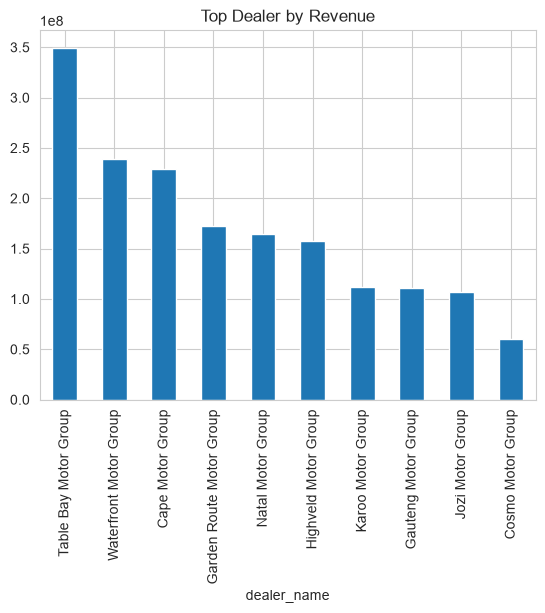

In [48]:
dealer_sales = (
    df.groupby('dealer_name')
    ['sale_price_zar']
    .sum()
    .sort_values(ascending=False)
)

dealer_sales.head(10).plot(
    kind='bar'
)
plt.title("Top Dealer by Revenue")
plt.show()

Table Bay Motor generated highest revenue of R3.4 million, making it the top-performing dealership in the dataset. The other dealerships that generated high revenue are Waterfront Motor Group (R2.3 million) and Cape Motor Group (R2.2 million), then the revenue started to decrease on the other following dealerships. The dealership that generted the lowest revenue is Cosmo Motor Group (less than R700 000.00).

### 6.3 Monthly Trends 

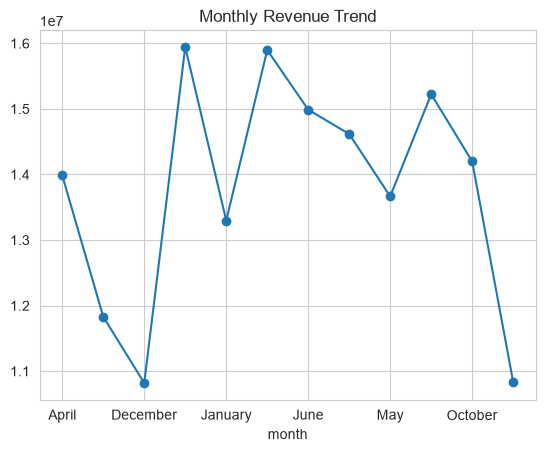

In [49]:
monthly_sales = ( 
    df.groupby('month')
    ['sale_price_zar']
    .sum()
)

monthly_sales.plot(
    kind='line', 
    marker='o'
)
plt.title("Monthly Revenue Trend")
plt.show()

Revenue peaked in between January and June (R1.5 million), indicating vehicle demand during these months. Lower sales observed in September and December (less than R1.1 million) may suggests fluctuations in customer purchasing. 

### 6.4 Best-Selling Brands 

<Axes: ylabel='make'>

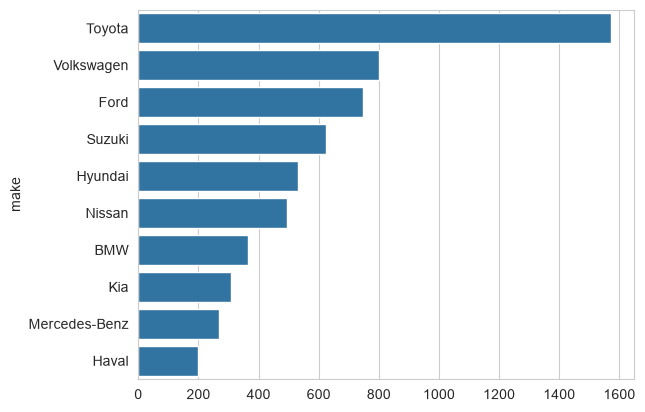

In [52]:
brand_sales = ( 
    df.groupby('make')
    .size()
    .sort_values(ascending=False)
) 

sns.barplot(
    x=brand_sales.values[:10],
    y=brand_sales.index[:10]
)

Toyota was the best-selling brand, recording the highest number of vehicle sales of 1500. The other brands that sold highest number of vehicle are Volkswagen (800 vehicles), Ford (700 vehicles) and Suzuki (600 vehicles). The brand that sold the least on the visualization is Haval (less than 200 vehicles). 

### 6.5 Correlation Analysis 

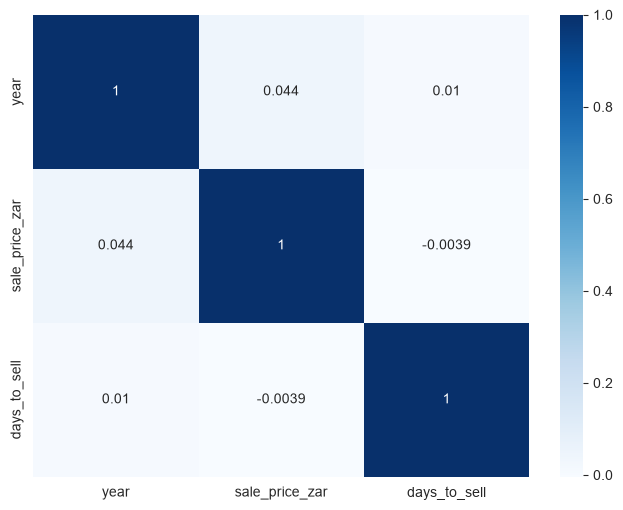

In [44]:
plt.figure(figsize=(8,6))
sns.heatmap(
    df.select_dtypes(include='number')
    .corr(),
    annot=True,
    cmap='Blues'
    )
plt.show()

The correlation analysis shows that the year in which the model made is corelated with the sales price (0.444) so this means they have a quite positive relationship. Then days to sell  and sales of the vehicles have a negative relationship (-0.0039) suggesting that the time taken to sell a vehicle has little influence on its selling price. 

## 7. Conclusion 

The exploratory data analysis revealed that the vehicle sales business generated approximately **R1.74 billion in revenue**, with an average vehicle selling price of **R248,015.64**, indicating strong sales activity across the dealerships. 

Dealer performance analysis showed that **Table Bay Motor** was the top-performing dealership, generating the highest revenue, while **Cosmo Motor Group** generated the lowest revenue among the dealerships analyzed. This suggests differences in sales performance and market reach across dealerships. 

The monthly sales analysis indicated that vehicle sales were stronger during the first half of the year, particularly between **January and June**, while sales declined during **September and December**, suggesting the presence of seasonal purchasing patterns.

Brand analysis showed that **Toyota** was the most popular vehicle brand, significantly outperforming competitors in terms of sales volume. **Volkswagen, Ford, and Suzuki** also recorded strong sales figures, while **Haval** recorded the lowest sales among the brands displayed. 

Correlation analysis revealed a moderate positive relationship between **vehicle model year** and **sale price**, indicating that newer vehicles tend to sell at higher prices. In contrast, the relationship between **days_to_sell** and **sale_price_zar** was extremely weak, suggesting that the time taken to sell a vehicle has little influence on its selling price within this dataset. 

Overall, the analysis suggests that dealership performance, vehicle brand popularity, and seasonality are important factors influencing vehicle sales. These insights can support business decisions related to inventory management, marketing strategies, and dealership performance improvement. 